In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load primary optimization results (10-minute SLA)
opt_df = pd.read_csv('optimization_results.csv')
opt_df['timestamp'] = pd.to_datetime(opt_df['timestamp'])

# Load data hasil eksperimen SLA
exp_df = pd.read_csv('experiment_sla_results.csv')

sns.set_theme(style="whitegrid")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_6936\1075295606.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=staff_data, x='Method', y='Total Staff-Hours', ax=axes[0], palette=['#e74c3c', '#2ecc71'])
C:\Users\ASUS\AppData\Local\Temp\ipykernel_6936\1075295606.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=violation_data, x='Method', y='Total Violations (Jam)', ax=axes[1], palette=['#e74c3c', '#2ecc71'])


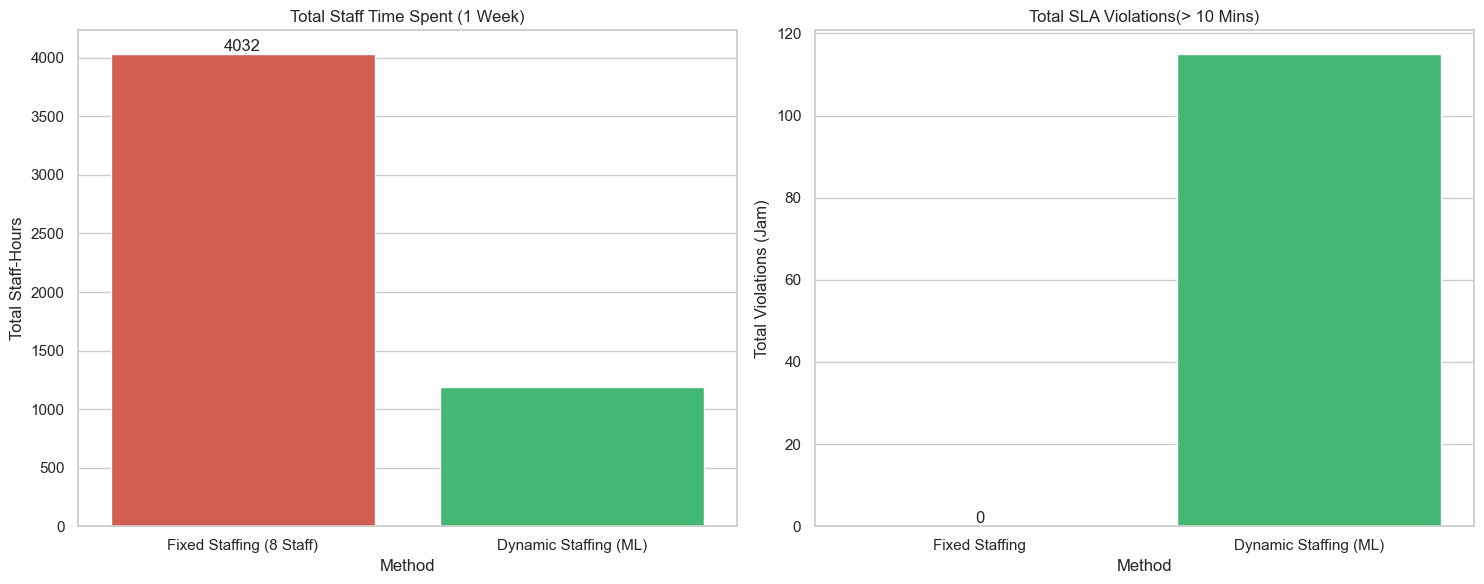

In [2]:
# ==========================================
# PLOT 1: Komparasi Kinerja (Staff-Hours & SLA)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Bar chart Staff-Hours
staff_data = pd.DataFrame({
    'Method': ['Fixed Staffing (8 Staff)', 'Dynamic Staffing (ML)'],
    'Total Staff-Hours': [opt_df['fixed_staff'].sum(), opt_df['dynamic_staff'].sum()]
})
sns.barplot(data=staff_data, x='Method', y='Total Staff-Hours', ax=axes[0], palette=['#e74c3c', '#2ecc71'])
axes[0].set_title('Total Staff Time Spent (1 Week)')
axes[0].bar_label(axes[0].containers[0])

# Bar chart SLA Violations
violation_data = pd.DataFrame({
    'Method': ['Fixed Staffing', 'Dynamic Staffing (ML)'],
    'Total Violations (Jam)': [opt_df['fixed_sla_violation'].sum(), opt_df['dynamic_sla_violation'].sum()]
})
sns.barplot(data=violation_data, x='Method', y='Total Violations (Jam)', ax=axes[1], palette=['#e74c3c', '#2ecc71'])
axes[1].set_title('Total SLA Violations(> 10 Mins)')
axes[1].bar_label(axes[1].containers[0])

plt.tight_layout()
plt.show()



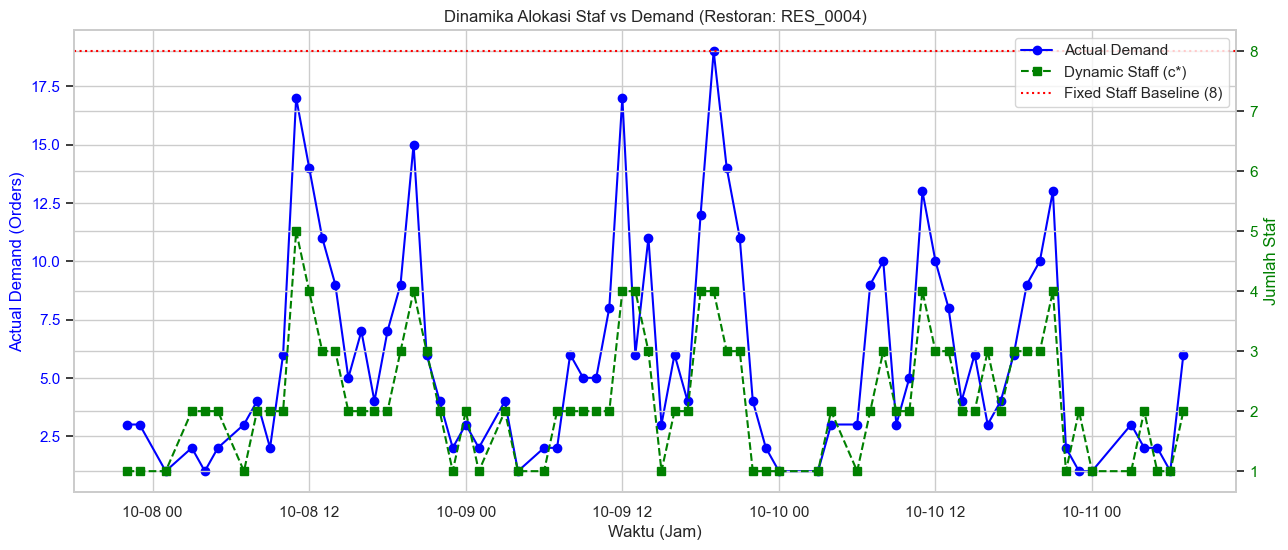

In [3]:
# ==========================================
# PLOT 2: Time-Series Demand vs Optimal Staff
# ==========================================
# Select one specific restaurant over a three-day period for visual clarity.
sample_rest = opt_df['restaurant_id'].unique()[0]
sample_df = opt_df[opt_df['restaurant_id'] == sample_rest].head(72) 

fig, ax1 = plt.subplots(figsize=(15, 6))

ax1.set_xlabel('Waktu (Jam)')
ax1.set_ylabel('Actual Demand (Orders)', color='blue')
ax1.plot(sample_df['timestamp'], sample_df['actual_demand'], color='blue', marker='o', label='Actual Demand')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()  
ax2.set_ylabel('Jumlah Staf', color='green')
ax2.plot(sample_df['timestamp'], sample_df['dynamic_staff'], color='green', linestyle='dashed', marker='s', label='Dynamic Staff (c*)')
ax2.axhline(y=8, color='red', linestyle='dotted', label='Fixed Staff Baseline (8)')
ax2.tick_params(axis='y', labelcolor='green')

plt.title(f'Dinamika Alokasi Staf vs Demand (Restoran: {sample_rest})')
fig.legend(loc="upper right", bbox_to_anchor=(1,1), bbox_transform=ax1.transAxes)
plt.show()

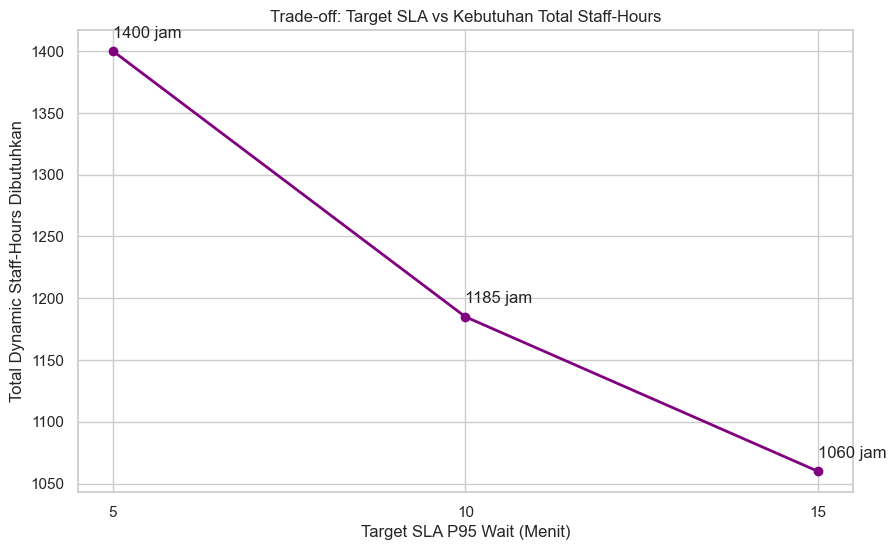

In [4]:
# ==========================================
# PLOT 3: Sensitivity Analysis (Cost vs SLA)
# ==========================================
plt.figure(figsize=(10, 6))
plt.plot(exp_df['SLA_Target_Mins'], exp_df['Dynamic_Total_Staff_Hours'], marker='o', color='purple', linewidth=2)
plt.title('Trade-off: Target SLA vs Kebutuhan Total Staff-Hours')
plt.xlabel('Target SLA P95 Wait (Menit)')
plt.ylabel('Total Dynamic Staff-Hours Dibutuhkan')
plt.xticks(exp_df['SLA_Target_Mins'])
for i, txt in enumerate(exp_df['Dynamic_Total_Staff_Hours']):
    plt.annotate(f"{txt} jam", (exp_df['SLA_Target_Mins'][i], exp_df['Dynamic_Total_Staff_Hours'][i]), xytext=(0, 10), textcoords='offset points')
plt.show()


In [5]:
# TABEL REKAPITULASI METRIK FINAL
print("=== METRIK EVALUASI FINAL SISTEM ANTRIAN ===")
summary_metrics = pd.DataFrame({
    'Metrik': [
        'Total Staff-Hours Needed',
        'Mean  Wait Time P95 (Menit)',
        'Demand Rate SLA (%)',
        'Efficiency Staff Reduction (%)'
    ],
    'Fixed Staffing': [
        opt_df['fixed_staff'].sum(),
        round(opt_df['fixed_p95_wait'].mean(), 2),
        f"{round((opt_df['fixed_sla_violation'].sum() / len(opt_df)) * 100, 2)}%",
        "-"
    ],
    'Dynamic Staffing (Proposed)': [
        opt_df['dynamic_staff'].sum(),
        round(opt_df['dynamic_p95_wait'].mean(), 2),
        f"{round((opt_df['dynamic_sla_violation'].sum() / len(opt_df)) * 100, 2)}%",
        f"{round((1 - opt_df['dynamic_staff'].sum() / opt_df['fixed_staff'].sum()) * 100, 2)}% Reduction"
    ]
})

print(summary_metrics.to_string(index=False))

=== METRIK EVALUASI FINAL SISTEM ANTRIAN ===
                        Metrik Fixed Staffing Dynamic Staffing (Proposed)
      Total Staff-Hours Needed           4032                        1190
   Mean  Wait Time P95 (Menit)           0.01                        5.99
           Demand Rate SLA (%)           0.0%                      22.82%
Efficiency Staff Reduction (%)              -            70.49% Reduction
